In [ ]:
#Its better to run in the google collabs :))

#https://colab.research.google.com/drive/1BIRrDEXd_WuXULT111Qu-YWY0f2i8l9A#scrollTo=8KDW4io5Oktl

#parquet_path = "/content/sample_data/customer_360_features.parquet"

In [34]:
parquet_path = 'customer_360_features.parquet'

In [35]:
#   Necesseary libaries

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report

In [36]:
#Estimating the total amount of run time

start_time = time.time()


In [37]:
# 1. LOADING THE DATA

spark = SparkSession.builder \
    .appName("PerfectPetClub_Churn_Prediction") \
    .master("local[*]") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

parquet_path = "/content/sample_data/customer_360_features.parquet"
sdf = spark.read.parquet(parquet_path) \
    .withColumn("label", F.col("is_churned").cast("double")) \
    .drop("is_churned")

print(f"Dataset Loaded: {sdf.count()} rows | {len(sdf.columns)} columns")
sdf.groupBy("label").count().show()

Dataset Loaded: 221 rows | 28 columns
+-----+-----+
|label|count|
+-----+-----+
|  0.0|  135|
|  1.0|   86|
+-----+-----+



In [38]:

# 2. DIVING THE DATA TO TRAIN / TEST SPLIT (80% / 20%) & CLASS WEIGHTING

train_active, test_active = sdf.filter(F.col("label") == 0.0).randomSplit([0.8, 0.2], seed=42)
train_churn, test_churn   = sdf.filter(F.col("label") == 1.0).randomSplit([0.8, 0.2], seed=42)

raw_train_df = train_active.union(train_churn)
raw_test_df  = test_active.union(test_churn)

total_train  = raw_train_df.count()
churn_count  = raw_train_df.filter(F.col("label") == 1.0).count()
active_count = total_train - churn_count

weight_churn  = total_train / (2.0 * churn_count)
weight_active = total_train / (2.0 * active_count)

raw_train_df = raw_train_df.withColumn(
    "classWeight",
    F.when(F.col("label") == 1.0, weight_churn).otherwise(weight_active)
)

print(f"Total Train: {total_train} | Total Churn: {churn_count} | Total Active Churn: {active_count}")

Total Train: 180 | Total Churn: 69 | Total Active Churn: 111


In [39]:
# 3. FEATURE ENGINEERING PIPELINE (USED HELPER FUNCTIONS TO REDUCING TO RUN TIME)

cat_cols = [c for c, dtype in sdf.dtypes if dtype == "string"]
num_cols = [c for c, dtype in sdf.dtypes if dtype != "string" and c != "label"]

indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in cat_cols]
encoders = [OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_ohe") for c in cat_cols]

num_assembler = VectorAssembler(inputCols=num_cols, outputCol="num_features", handleInvalid="keep")
scaler        = StandardScaler(inputCol="num_features", outputCol="scaled_num_features", withStd=True, withMean=False)

final_inputs    = ["scaled_num_features"] + [f"{c}_ohe" for c in cat_cols]
final_assembler = VectorAssembler(inputCols=final_inputs, outputCol="features", handleInvalid="keep")

preprocess_pipeline = Pipeline(stages=indexers + encoders + [num_assembler, scaler, final_assembler])
preprocess_model    = preprocess_pipeline.fit(raw_train_df)

train_df = preprocess_model.transform(raw_train_df).select("features", "label", "classWeight").repartition(4).cache()
test_df  = preprocess_model.transform(raw_test_df).select("features", "label").repartition(4).cache()

print(f"Train Rows: {train_df.count()} | Test Rows: {test_df.count()}")

Train Rows: 180 | Test Rows: 41


In [40]:
# 4. MODEL DEFINITIONS & FAST HYPERPARAMETER GRIDS
# ==============================================================================

evaluator_auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
evaluator_f1  = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
evaluator_acc = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")

# 1. Logistic Regression (Linear Baseline)
lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="classWeight", maxIter=30)
lr_grid = ParamGridBuilder() \
    .addGrid(lr.regParam, [0.01, 0.1]) \
    .build()

# 2. Decision Tree Classifier (Interpretable Rule-Based Tree)
dt = DecisionTreeClassifier(featuresCol="features", labelCol="label", weightCol="classWeight", seed=42)
dt_grid = ParamGridBuilder() \
    .addGrid(dt.maxDepth, [4, 6]) \
    .addGrid(dt.minInstancesPerNode, [5, 10]) \
    .build()

# 3. Random Forest Classifier (Ensemble Bagging)
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="classWeight", numTrees=60, seed=42)
rf_grid = ParamGridBuilder() \
    .addGrid(rf.maxDepth, [5, 7]) \
    .build()

models = {
    "Logistic Regression": (lr, lr_grid),
    "Decision Tree":       (dt, dt_grid),
    "Random Forest":       (rf, rf_grid)
}


In [41]:

# 5. 3-FOLD CROSS-VALIDATION & EVALUATION

results = []
best_models = {}

for name, (classifier, grid) in models.items():
    t0 = time.time()
    cv = CrossValidator(
        estimator=classifier,
        estimatorParamMaps=grid,
        evaluator=evaluator_auc,
        numFolds=3,
        parallelism=2,
        seed=42
    )
    cv_model = cv.fit(train_df)
    best_model = cv_model.bestModel
    best_models[name] = best_model

    predictions = best_model.transform(test_df).cache()
    results.append({
        "Model":           name,
        "CV ROC-AUC":      round(max(cv_model.avgMetrics), 3),
        "Test ROC-AUC":    round(evaluator_auc.evaluate(predictions), 3),
        "Test F1-Score":   round(evaluator_f1.evaluate(predictions), 3),
        "Test Accuracy":   round(evaluator_acc.evaluate(predictions), 3)
    })
    print(f"[DONE] {name} trained in {time.time() - t0:.1f}s")

results_df = pd.DataFrame(results).sort_values(by="Test ROC-AUC", ascending=False)
print("\n=== Model Performance Comparison ===")
print(results_df.to_string(index=False))

[DONE] Logistic Regression trained in 18.3s
[DONE] Decision Tree trained in 19.5s
[DONE] Random Forest trained in 18.3s

=== Model Performance Comparison ===
              Model  CV ROC-AUC  Test ROC-AUC  Test F1-Score  Test Accuracy
Logistic Regression       0.628         0.789          0.734          0.732
      Random Forest       0.715         0.752          0.721          0.732
      Decision Tree       0.685         0.668          0.749          0.756


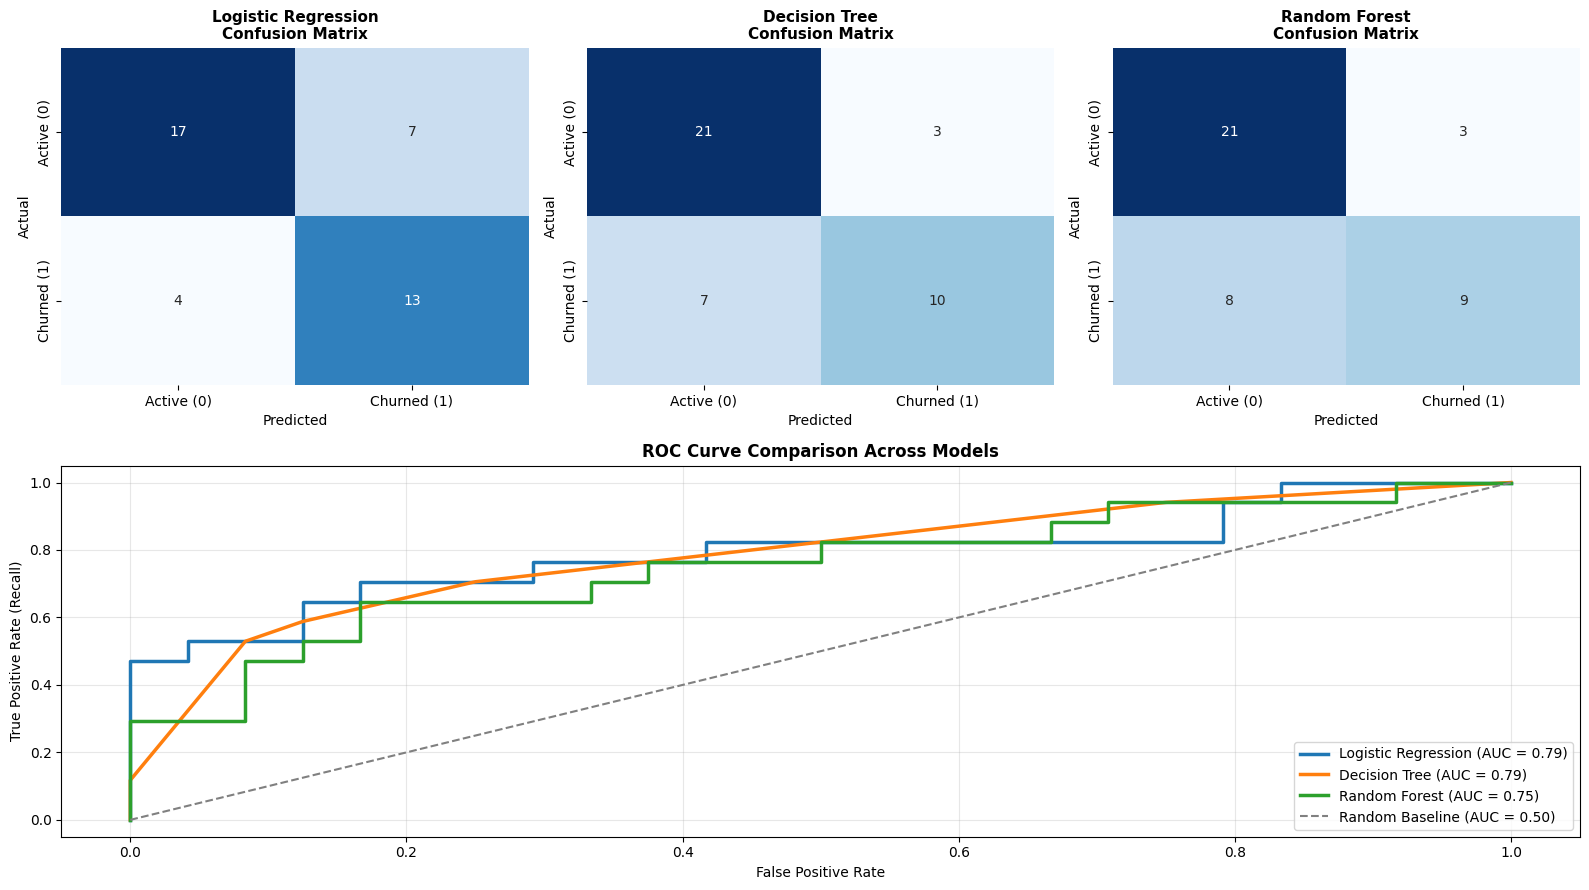

In [42]:

# 6. VISUALIZATION 1: CONFUSION MATRICES (1st) & ROC CURVES (2nd)

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])

cm_axes = [fig.add_subplot(gs[0, i]) for i in range(3)]
roc_ax  = fig.add_subplot(gs[1, :])

for idx, (name, model) in enumerate(best_models.items()):
    preds_pd = model.transform(test_df).select("label", "prediction", "probability").toPandas()
    y_true = preds_pd["label"].values
    y_pred = preds_pd["prediction"].values
    y_prob = np.array([p[1] for p in preds_pd["probability"]])

    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=cm_axes[idx],
        xticklabels=["Active (0)", "Churned (1)"],
        yticklabels=["Active (0)", "Churned (1)"]
    )
    cm_axes[idx].set_title(f"{name}\nConfusion Matrix", fontsize=11, fontweight="bold")
    cm_axes[idx].set_xlabel("Predicted")
    cm_axes[idx].set_ylabel("Actual")

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_ax.plot(fpr, tpr, lw=2.5, label=f"{name} (AUC = {auc(fpr, tpr):.2f})")

roc_ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Baseline (AUC = 0.50)")
roc_ax.set_title("ROC Curve Comparison Across Models", fontsize=12, fontweight="bold")
roc_ax.set_xlabel("False Positive Rate")
roc_ax.set_ylabel("True Positive Rate (Recall)")
roc_ax.legend(loc="lower right")
roc_ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


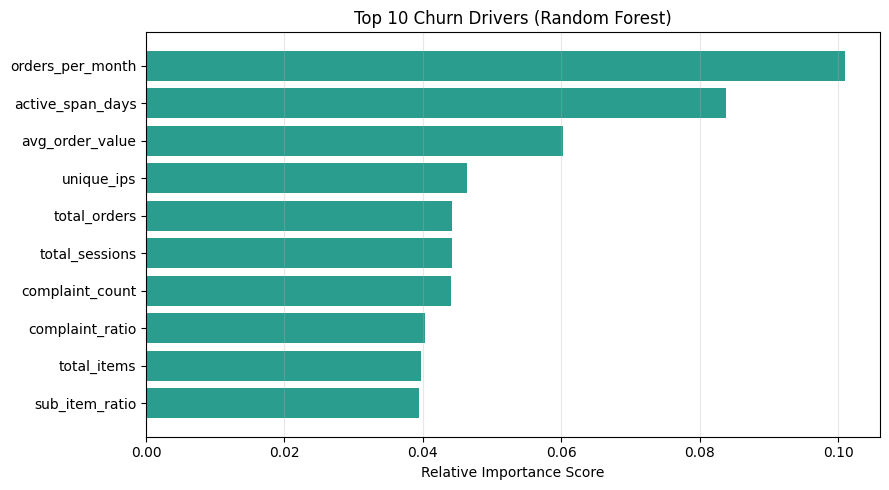

In [43]:

# 7. VISUALIZATION 2: TOP 10 CHURN DRIVERS (FEATURE IMPORTANCE)

rf_auc = results_df.loc[results_df["Model"] == "Random Forest", "Test ROC-AUC"].values[0]
dt_auc = results_df.loc[results_df["Model"] == "Decision Tree", "Test ROC-AUC"].values[0]
best_tree_name = "Random Forest" if rf_auc >= dt_auc else "Decision Tree"

attrs = test_df.schema["features"].metadata["ml_attr"]["attrs"]
feature_map = {}
for attr_type in ["numeric", "binary", "nominal"]:
    for attr in attrs.get(attr_type, []):
        name = attr["name"]
        if name.startswith("scaled_num_features_"):
            name = num_cols[int(name.split("_")[-1])]
        feature_map[attr["idx"]] = name

ordered_features = [feature_map[i] for i in sorted(feature_map)]
importances = best_models[best_tree_name].featureImportances.toArray()

top_features_df = pd.DataFrame({
    "Feature": ordered_features,
    "Importance": importances
}).sort_values(by="Importance", ascending=False).head(10)

plt.figure(figsize=(9, 5))
plt.barh(top_features_df["Feature"][::-1], top_features_df["Importance"][::-1], color="#2a9d8f")
plt.xlabel("Relative Importance Score")
plt.title(f"Top 10 Churn Drivers ({best_tree_name})")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [44]:

# 8. DETAILED CLASSIFICATION REPORT FOR THE BEST MODEL

winner_name = results_df.iloc[0]["Model"]
winner_preds = best_models[winner_name].transform(test_df).select("label", "prediction").toPandas()

print(f"\n=== Detailed Classification Report: {winner_name} ===")
print(classification_report(winner_preds["label"], winner_preds["prediction"], target_names=["Active (0)", "Churned (1)"]))
print(f"Total Pipeline Runtime: {time.time() - start_time:.1f} seconds")




=== Detailed Classification Report: Logistic Regression ===
              precision    recall  f1-score   support

  Active (0)       0.81      0.71      0.76        24
 Churned (1)       0.65      0.76      0.70        17

    accuracy                           0.73        41
   macro avg       0.73      0.74      0.73        41
weighted avg       0.74      0.73      0.73        41

Total Pipeline Runtime: 66.6 seconds


In [45]:
#WITH ADDITIONAL GRAPH TO UNDERSTANDING AI MODEL PERFORMANCE BETTER

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score
)

full_pd = sdf.toPandas()
full_pd["Churn_Status"] = full_pd["label"].map({0.0: "Active (0)", 1.0: "Churned (1)"})

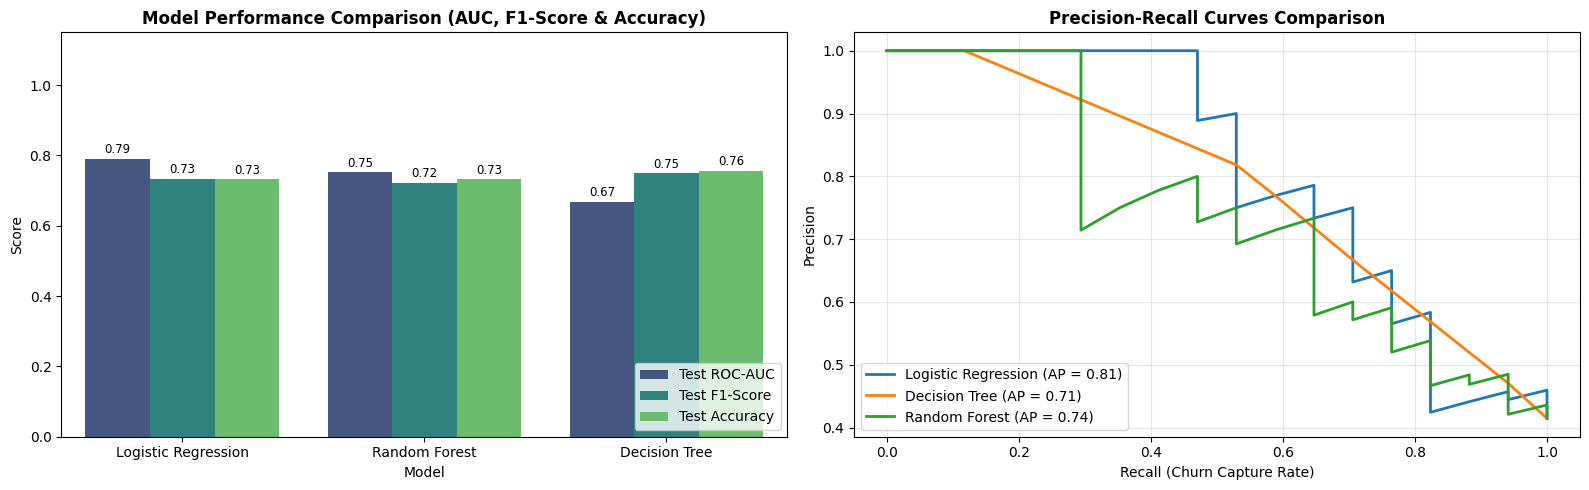

In [47]:

# 1. MODEL COMPARISON (AUC, F1, ACCURACY) & PRECISION-RECALL

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

metrics_melted = results_df.melt(
    id_vars="Model",
    value_vars=["Test ROC-AUC", "Test F1-Score", "Test Accuracy"],
    var_name="Metric",
    value_name="Score"
)
sns.barplot(data=metrics_melted, x="Model", y="Score", hue="Metric", palette="viridis", ax=axes[0])
axes[0].set_title("Model Performance Comparison (AUC, F1-Score & Accuracy)", fontsize=12, fontweight="bold")
axes[0].set_ylim(0, 1.15)
axes[0].legend(loc="lower right")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", fontsize=8.5, padding=2)

for name, model in best_models.items():
    preds_pd = model.transform(test_df).select("label", "probability").toPandas()
    y_true = preds_pd["label"].values
    y_prob = np.array([p[1] for p in preds_pd["probability"]])
    prec, rec, _ = precision_recall_curve(y_true, y_prob)
    ap_score = average_precision_score(y_true, y_prob)
    axes[1].plot(rec, prec, lw=2, label=f"{name} (AP = {ap_score:.2f})")

axes[1].set_title("Precision-Recall Curves Comparison", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall (Churn Capture Rate)")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

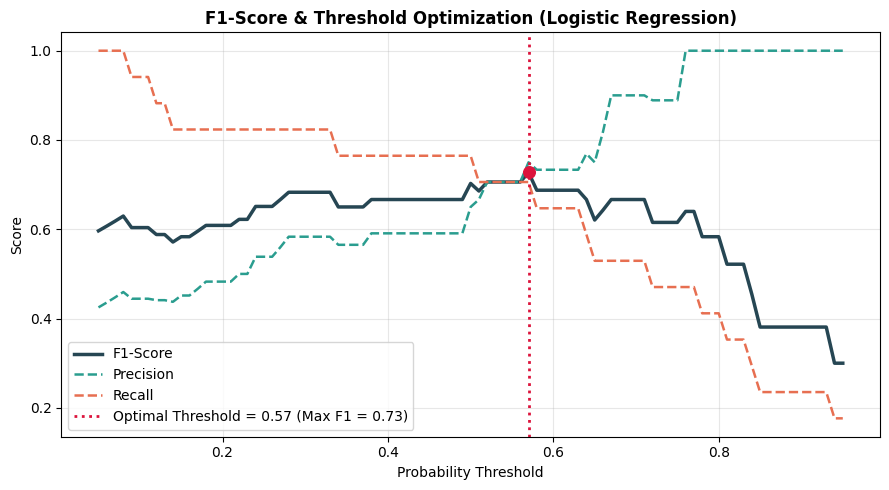

In [48]:
# 2. OPTIMAL F1 SCORE

overall_best_name = results_df.iloc[0]["Model"]
best_preds_df = best_models[overall_best_name].transform(test_df).select("label", "probability").toPandas()
y_true = best_preds_df["label"].values
y_prob = np.array([p[1] for p in best_preds_df["probability"]])

thresholds = np.linspace(0.05, 0.95, 91)
f1_scores = [f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
prec_scores = [precision_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
rec_scores = [recall_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]

best_idx = int(np.argmax(f1_scores))
best_thresh, best_f1_val = thresholds[best_idx], f1_scores[best_idx]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(thresholds, f1_scores, label="F1-Score", color="#264653", lw=2.5)
ax.plot(thresholds, prec_scores, label="Precision", color="#2a9d8f", linestyle="--", lw=1.8)
ax.plot(thresholds, rec_scores, label="Recall", color="#e76f51", linestyle="--", lw=1.8)
ax.axvline(best_thresh, color="crimson", linestyle=":", lw=2, label=f"Optimal Threshold = {best_thresh:.2f} (Max F1 = {best_f1_val:.2f})")
ax.scatter([best_thresh], [best_f1_val], color="crimson", s=70, zorder=5)

ax.set_title(f"F1-Score & Threshold Optimization ({overall_best_name})", fontsize=12, fontweight="bold")
ax.set_xlabel("Probability Threshold")
ax.set_ylabel("Score")
ax.legend(loc="best")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


/tmp/ipykernel_1582/320256670.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_counties, x="churn_pct", y="customer_county", palette="Reds_r", ax=axes[0])
/tmp/ipykernel_1582/320256670.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plan_stats, x="last_sub_plan", y="churn_pct", palette="magma", ax=axes[1])


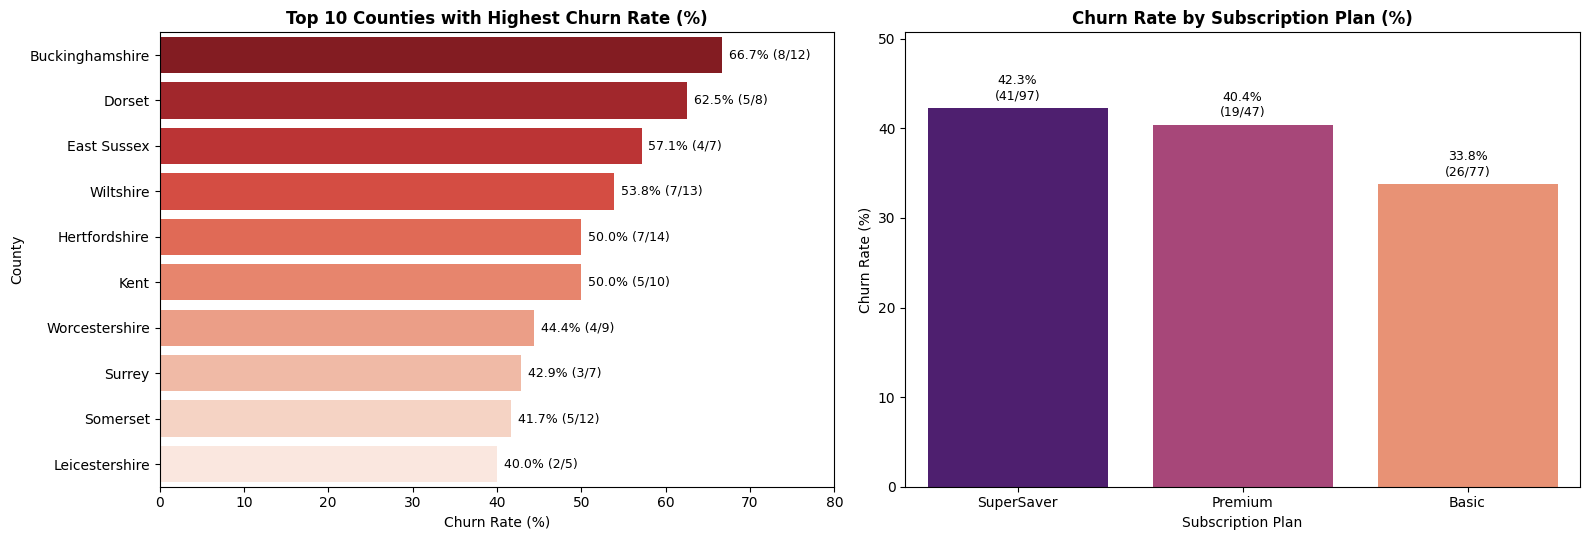

In [49]:

# 3. CHURN RATE BY COUNTY (TOP 10) & SUBSCRIPTION PLAN


fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

if "customer_county" in full_pd.columns:
    county_stats = full_pd.groupby("customer_county").agg(
        total_customers=("label", "count"),
        churned_customers=("label", "sum"),
        churn_rate=("label", "mean")
    ).reset_index()
    meaningful = county_stats[county_stats["total_customers"] >= 5]
    if len(meaningful) < 5:
        meaningful = county_stats
    top_counties = meaningful.sort_values(by=["churn_rate", "churned_customers"], ascending=False).head(10)
    top_counties["churn_pct"] = top_counties["churn_rate"] * 100

    sns.barplot(data=top_counties, x="churn_pct", y="customer_county", palette="Reds_r", ax=axes[0])
    axes[0].set_title("Top 10 Counties with Highest Churn Rate (%)", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Churn Rate (%)")
    axes[0].set_ylabel("County")
    axes[0].set_xlim(0, top_counties["churn_pct"].max() * 1.2)
    for idx, row in enumerate(top_counties.itertuples()):
        axes[0].text(row.churn_pct + 0.8, idx, f"{row.churn_pct:.1f}% ({int(row.churned_customers)}/{row.total_customers})", va="center", fontsize=9)

if "last_sub_plan" in full_pd.columns:
    plan_stats = full_pd.groupby("last_sub_plan").agg(
        total_customers=("label", "count"),
        churned_customers=("label", "sum"),
        churn_rate=("label", "mean")
    ).reset_index().sort_values(by="churn_rate", ascending=False)
    plan_stats["churn_pct"] = plan_stats["churn_rate"] * 100

    sns.barplot(data=plan_stats, x="last_sub_plan", y="churn_pct", palette="magma", ax=axes[1])
    axes[1].set_title("Churn Rate by Subscription Plan (%)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Subscription Plan")
    axes[1].set_ylabel("Churn Rate (%)")
    axes[1].set_ylim(0, plan_stats["churn_pct"].max() * 1.2)
    for idx, row in enumerate(plan_stats.itertuples()):
        axes[1].text(idx, row.churn_pct + 1.0, f"{row.churn_pct:.1f}%\n({int(row.churned_customers)}/{row.total_customers})", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

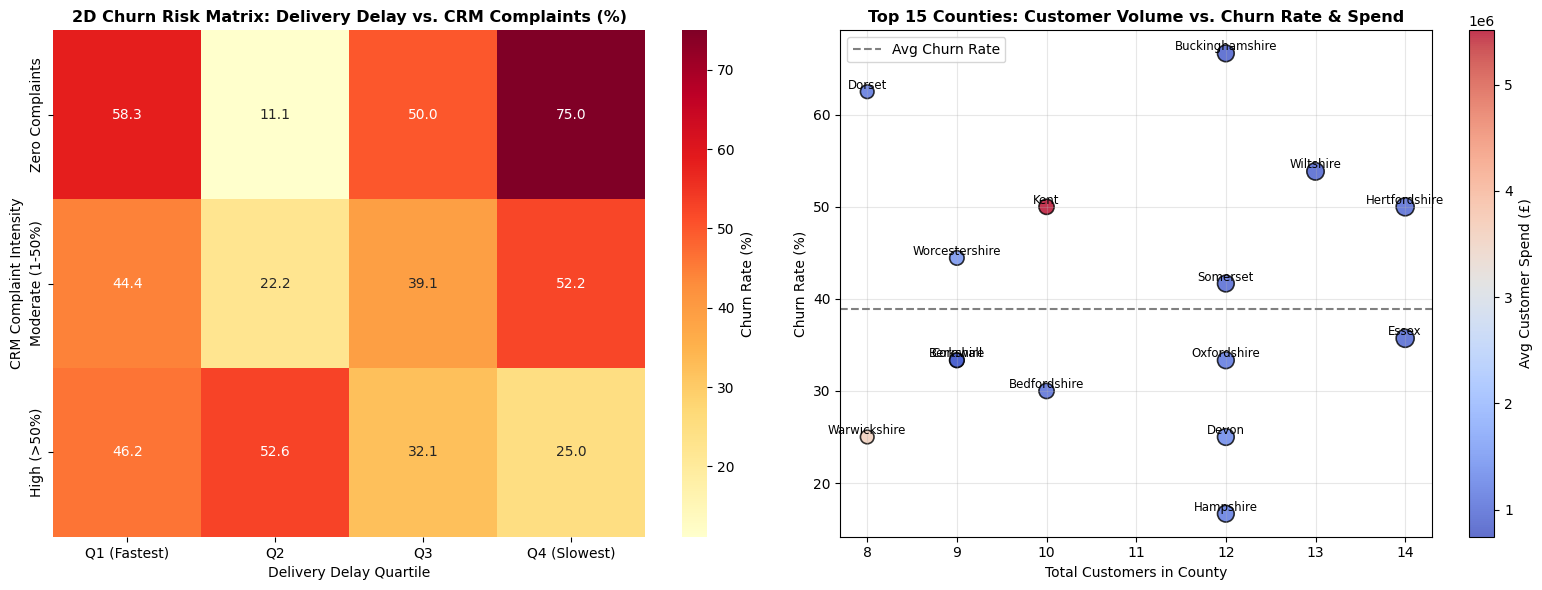

In [50]:

# 4. 2D RISK MATRIX & COUNTY VOLUME VS CHURN BUBBLE CHART


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

if "avg_delivery_delay" in full_pd.columns and "complaint_ratio" in full_pd.columns:
    temp_df = full_pd.copy()
    temp_df["Delay_Tier"] = pd.qcut(temp_df["avg_delivery_delay"].rank(method="first"), q=4, labels=["Q1 (Fastest)", "Q2", "Q3", "Q4 (Slowest)"])
    temp_df["Complaint_Tier"] = pd.cut(temp_df["complaint_ratio"], bins=[-0.01, 0.0, 0.5, 1.0], labels=["Zero Complaints", "Moderate (1-50%)", "High (>50%)"])
    pivot_churn = temp_df.pivot_table(index="Complaint_Tier", columns="Delay_Tier", values="label", aggfunc="mean", observed=False) * 100
    sns.heatmap(pivot_churn, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Churn Rate (%)"}, ax=axes[0])
    axes[0].set_title("2D Churn Risk Matrix: Delivery Delay vs. CRM Complaints (%)", fontsize=11.5, fontweight="bold")
    axes[0].set_xlabel("Delivery Delay Quartile")
    axes[0].set_ylabel("CRM Complaint Intensity")

if "customer_county" in full_pd.columns:
    county_agg = full_pd.groupby("customer_county").agg(
        customers=("label", "count"),
        churn_rate=("label", lambda x: x.mean() * 100),
        avg_spend=("total_spend", "mean") if "total_spend" in full_pd.columns else ("label", "count")
    ).reset_index()
    top_vol = county_agg.sort_values(by="customers", ascending=False).head(15)
    scatter = axes[1].scatter(
        top_vol["customers"], top_vol["churn_rate"],
        s=top_vol["customers"] * 12, c=top_vol["avg_spend"],
        cmap="coolwarm", alpha=0.8, edgecolors="black", linewidth=1.2
    )
    plt.colorbar(scatter, ax=axes[1], label="Avg Customer Spend (£)")
    for _, row in top_vol.iterrows():
        axes[1].annotate(row["customer_county"], (row["customers"], row["churn_rate"]), fontsize=8.5, ha="center", va="bottom")
    axes[1].axhline(full_pd["label"].mean() * 100, color="gray", linestyle="--", label="Avg Churn Rate")
    axes[1].set_title("Top 15 Counties: Customer Volume vs. Churn Rate & Spend", fontsize=11.5, fontweight="bold")
    axes[1].set_xlabel("Total Customers in County")
    axes[1].set_ylabel("Churn Rate (%)")
    axes[1].legend(loc="best")
    axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

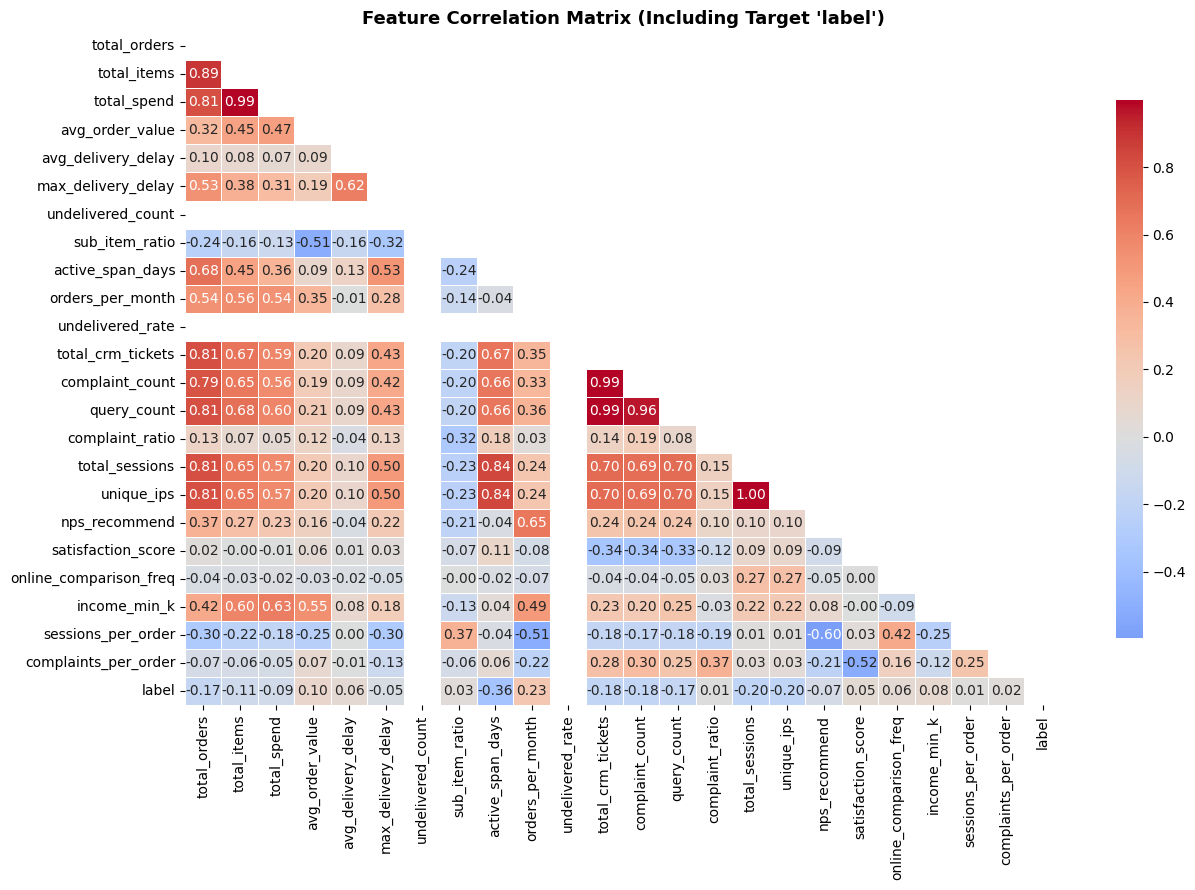

In [51]:

# 6. FEATURE CORRELATION HEATMAP


numeric_df = full_pd.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(13, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix (Including Target 'label')", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [1]:

#CONVERTING IPYNB TO HTML

import subprocess, sys, os

notebooks = [
    "ELT.ipynb",
    "ML.ipynb",
    "Pre_Processed_Data.ipynb"
]

def export_all_to_html(nb_list):
    print(f"Working directory: {os.getcwd()}\n")
    for nb in nb_list:
        if not os.path.exists(nb):
            print(f"[NOT FOUND] {nb}")
            continue

        subprocess.run(
            [sys.executable, "-m", "jupyter", "nbconvert", "--to", "html", nb],
            check=True
        )
        html_path = os.path.abspath(nb.replace(".ipynb", ".html"))
        print(f"[OK] {nb} -> {html_path}")

export_all_to_html(notebooks)

Working directory: c:\Users\berkay\source\repos\customer-churn-prediction\notebooks

[OK] ELT.ipynb -> c:\Users\berkay\source\repos\customer-churn-prediction\notebooks\ELT.html
[OK] ML.ipynb -> c:\Users\berkay\source\repos\customer-churn-prediction\notebooks\ML.html
[OK] Pre_Processed_Data.ipynb -> c:\Users\berkay\source\repos\customer-churn-prediction\notebooks\Pre_Processed_Data.html
